# SpaceX Falcon 9 first-stage landing analysis

IBM Applied Data Science Capstone. Reproducible analysis of the official course snapshots, accessed 21 October 2026. The model targets first-stage landing success, not mission success. API and web datasets have different populations and are analyzed separately. AI assistance was used to prepare the code and report.


In [1]:
import json, sqlite3, re, unicodedata
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
from IPython.display import display
BASE=Path.cwd()
sns.set_theme(style='whitegrid', palette='colorblind')
raw=pd.json_normalize(json.loads((BASE/'api_snapshot.json').read_text()))
print('First static fire:',raw.iloc[0]['static_fire_date_utc'])
api=raw[raw.cores.map(len).eq(1)&raw.payloads.map(len).eq(1)].copy()
api=api[pd.to_datetime(api.date_utc).dt.date.astype(str).le('2020-11-13')]
api=api[api.rocket.ne('5e9d0d95eda69955f709d1eb')]
print('Falcon 9 launches:',len(api))
print('Missing landing pads:',sum(c[0]['landpad'] is None for c in api.cores))
df=pd.read_csv(BASE/'dataset_part_1.csv')
assert len(df)==len(api)==90
display(df.head())


First static fire: 2006-03-17T00:00:00.000Z
Falcon 9 launches: 90
Missing landing pads: 26


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857


## Web collection
The official lab requests the Wikipedia revision `oldid=1027686922`. BeautifulSoup selects launch tables and numeric flight rows, then strips reference markers and normalizes whitespace. This notebook preserves the raw HTML and extracted records so changes in the live site cannot alter the results. The separate official SQL CSV contains 101 records and retains historical site labels.

In [2]:
soup=BeautifulSoup((BASE/'wikipedia_snapshot.html').read_text(),'html.parser')
print(soup.title)
records=[]
for table in soup.select('table.wikitable'):
    for tr in table.find_all('tr'):
        th=tr.find('th')
        td=tr.find_all('td',recursive=False)
        if th and th.get_text(strip=True).isdigit() and len(td)>=9:
            vals=[]
            for cell in td[:9]:
                for ref in cell.select('sup.reference'): ref.decompose()
                vals.append(unicodedata.normalize('NFKC',cell.get_text(' ',strip=True)))
            records.append([int(th.get_text(strip=True))]+vals)
web=pd.DataFrame(records,columns=['FlightNumber','DateTime','BoosterVersion','LaunchSite','Payload','PayloadMass','Orbit','Customer','MissionOutcome','LandingOutcome'])
web=web.drop_duplicates(['FlightNumber','DateTime'])
web.to_csv(BASE/'web_launches.csv',index=False)
print('Extracted flight rows:',len(web)); display(web.head())


<title>List of Falcon 9 and Falcon Heavy launches - Wikipedia</title>
Extracted flight rows: 121


,FlightNumber,DateTime,BoosterVersion,LaunchSite,Payload,PayloadMass,Orbit,Customer,MissionOutcome,LandingOutcome
0,1,"4 June 2010, 18:45",F9 v1.0 B0003.1,"CCAFS , SLC-40",Dragon Spacecraft Qualification Unit,,LEO,SpaceX,Success,Failure (parachute)
1,2,"8 December 2010, 15:43",F9 v1.0 B0004.1,"CCAFS , SLC-40",Dragon demo flight C1 (Dragon C101),,LEO ( ISS ),NASA ( COTS ) NRO,Success,Failure (parachute)
2,3,"22 May 2012, 07:44",F9 v1.0 B0005.1,"CCAFS , SLC-40",Dragon demo flight C2+ (Dragon C102),"525 kg (1,157 lb)",LEO ( ISS ),NASA ( COTS ),Success,No attempt
3,4,"8 October 2012, 00:35",F9 v1.0 B0006.1,"CCAFS , SLC-40",SpaceX CRS-1 (Dragon C103),"4,700 kg (10,400 lb)",LEO ( ISS ),NASA ( CRS ),Success,No attempt
4,5,"1 March 2013, 15:10",F9 v1.0 B0007.1,"CCAFS , SLC-40",SpaceX CRS-2 (Dragon C104),"4,877 kg (10,752 lb)",LEO ( ISS ),NASA ( CRS ),Success,No attempt


## Data wrangling
The course API enrichment joins rocket, payload, launchpad and core IDs with their metadata. `dataset_part_1.csv` is the official saved result of that process. Payload mass already contains mean imputation in this snapshot. Missing landing-pad IDs indicate no recorded pad and remain explicit. Labels follow the course definition: True ASDS, True RTLS and True Ocean are class 1. All other outcomes are class 0.

In [3]:
display(df.isna().sum().to_frame('missing'))
df['Class']=df.Outcome.str.startswith('True').astype(int)
df['Year']=pd.to_datetime(df.Date).dt.year
df.to_csv(BASE/'dataset_part_2.csv',index=False)
display(df.LaunchSite.value_counts().to_frame('launches'))
display(df.Orbit.value_counts().to_frame('launches'))
display(df.Outcome.value_counts().to_frame('launches'))
print('Landing success:',df.Class.sum(),'/',len(df),'=',df.Class.mean())
features=df[['FlightNumber','PayloadMass','Orbit','LaunchSite','Flights','GridFins','Reused','Legs','LandingPad','Block','ReusedCount','Serial']]
features_one_hot=pd.get_dummies(features,columns=['Orbit','LaunchSite','LandingPad','Serial']).astype(float)
features_one_hot.to_csv(BASE/'dataset_part_3.csv',index=False)
print('Encoded shape:',features_one_hot.shape)


,missing
FlightNumber,0
Date,0
BoosterVersion,0
PayloadMass,0
Orbit,0
LaunchSite,0
Outcome,0
Flights,0
GridFins,0
Reused,0


,launches
LaunchSite,
CCAFS SLC 40,55
KSC LC 39A,22
VAFB SLC 4E,13


,launches
Orbit,
GTO,27
ISS,21
VLEO,14
PO,9
LEO,7
SSO,5
MEO,3
ES-L1,1
HEO,1


,launches
Outcome,
True ASDS,41
None None,19
True RTLS,14
False ASDS,6
True Ocean,5
False Ocean,2
None ASDS,2
False RTLS,1


Landing success: 60 / 90 = 0.6666666666666666
Encoded shape: (90, 80)


## Exploratory visualization
Scatter plots compare payload and flight sequence across sites and orbits. Bars describe landing rates, while annual means show historical change. Associations are descriptive and do not establish causality.

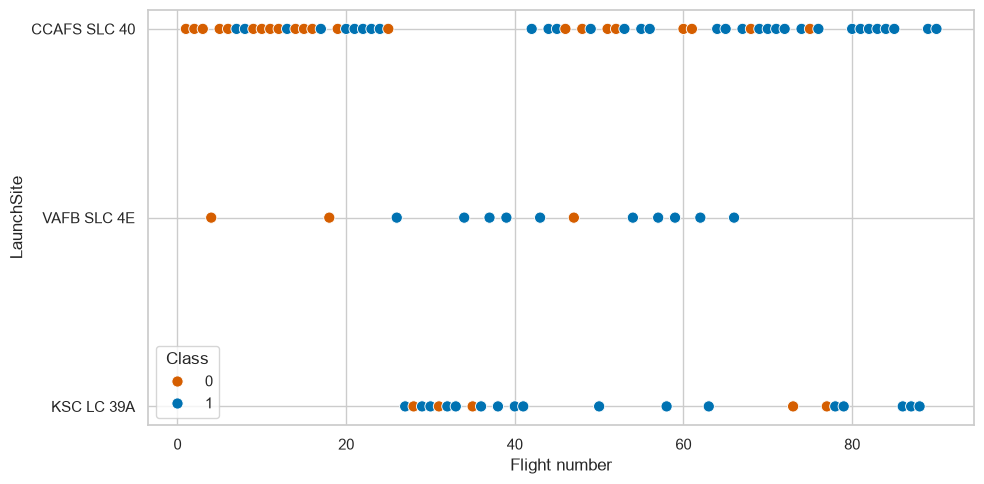

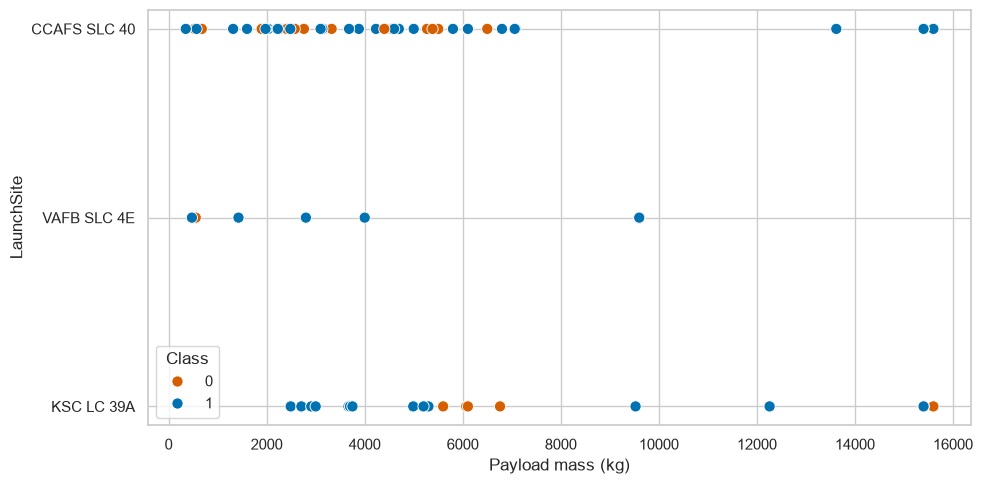

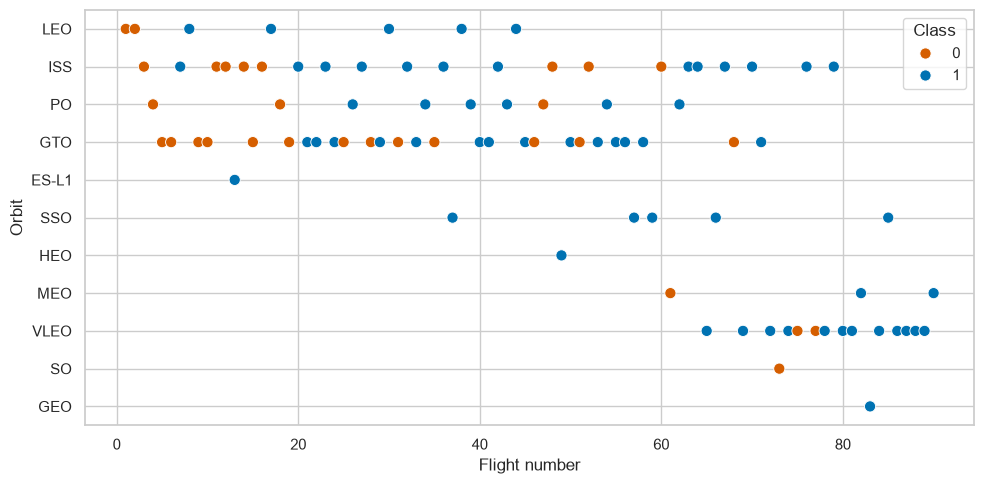

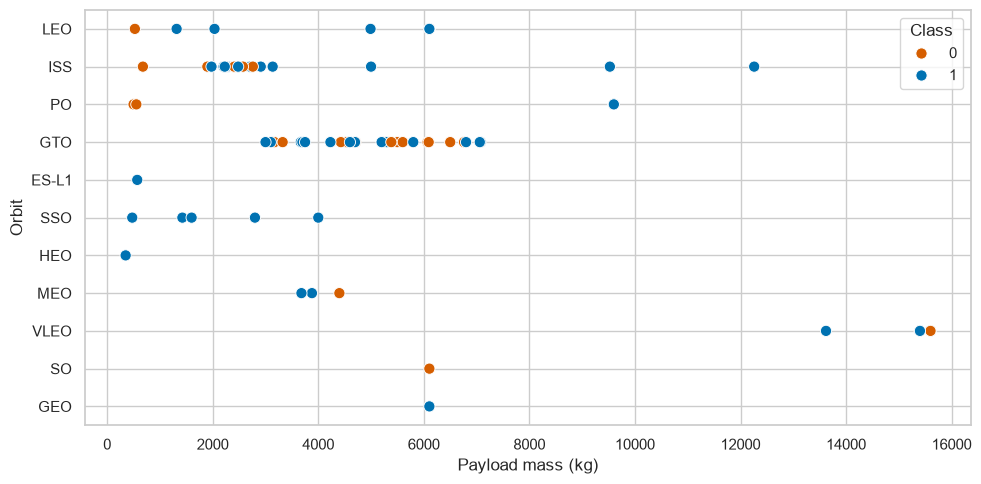

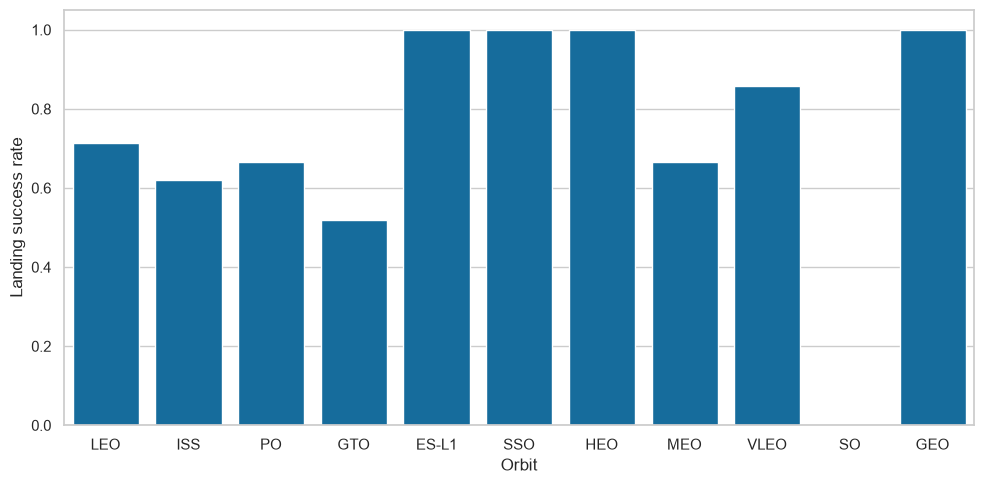

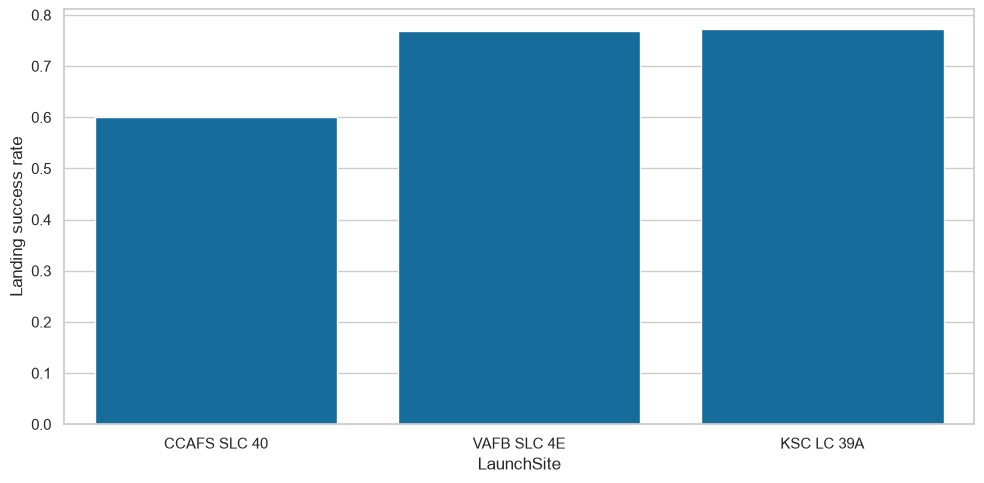

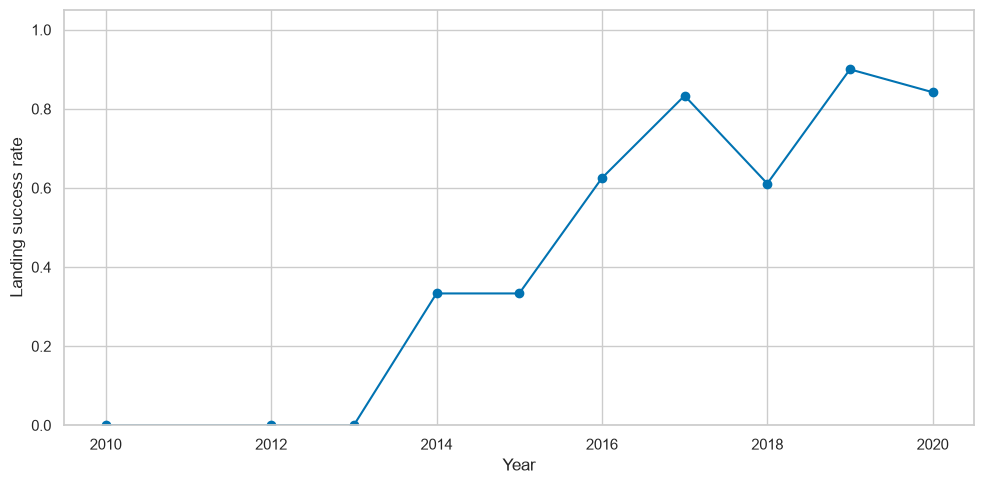

,mean,count,sum
LaunchSite,,,
CCAFS SLC 40,0.600000,55,33
KSC LC 39A,0.772727,22,17
VAFB SLC 4E,0.769231,13,10


,mean,count
Orbit,,
SO,0.000000,1
GTO,0.518519,27
ISS,0.619048,21
MEO,0.666667,3
PO,0.666667,9
LEO,0.714286,7
VLEO,0.857143,14
ES-L1,1.000000,1
GEO,1.000000,1


,mean,count,sum
Year,,,
2010,0.000000,1,0
2012,0.000000,1,0
2013,0.000000,3,0
2014,0.333333,6,2
2015,0.333333,6,2
2016,0.625000,8,5
2017,0.833333,18,15
2018,0.611111,18,11
2019,0.900000,10,9


In [4]:
def save(name):
    plt.tight_layout(); plt.savefig(BASE/(name+'.png'),dpi=160,bbox_inches='tight'); plt.show(); plt.close()
for x,y,name in [('FlightNumber','LaunchSite','flight_site'),('PayloadMass','LaunchSite','payload_site'),('FlightNumber','Orbit','flight_orbit'),('PayloadMass','Orbit','payload_orbit')]:
    plt.figure(figsize=(10,5));sns.scatterplot(data=df,x=x,y=y,hue='Class',palette={0:'#d55e00',1:'#0072b2'},s=65)
    plt.xlabel('Payload mass (kg)' if x=='PayloadMass' else 'Flight number'); save(name)
orbit=df.groupby('Orbit').Class.agg(['mean','count']).sort_values('mean')
plt.figure(figsize=(10,5));sns.barplot(data=df,x='Orbit',y='Class',errorbar=None,color='#0072b2');plt.ylabel('Landing success rate');save('orbit_success')
site=df.groupby('LaunchSite').Class.agg(['mean','count','sum'])
plt.figure(figsize=(10,5));sns.barplot(data=df,x='LaunchSite',y='Class',errorbar=None,color='#0072b2');plt.ylabel('Landing success rate');save('site_success')
year=df.groupby('Year').Class.agg(['mean','count','sum'])
plt.figure(figsize=(10,5));plt.plot(year.index,year['mean'],marker='o');plt.ylim(0,1.05);plt.xlabel('Year');plt.ylabel('Landing success rate');save('annual_success')
display(site);display(orbit);display(year)


## Exploratory analysis using SQL
The SQL population is the 101-row official `Spacex.csv`, rather than the filtered 90-row API dataset. Mission outcome and booster landing outcome have different meanings. Historical launch-site labels are retained as supplied.

In [5]:
sql_df=pd.read_csv(BASE/'Spacex.csv')
for col in sql_df.select_dtypes('object'): sql_df[col]=sql_df[col].str.strip()
con=sqlite3.connect(':memory:');sql_df.to_sql('SPACEXTBL',con,index=False)
queries={
'unique_sites':'SELECT DISTINCT Launch_Site FROM SPACEXTBL',
'cca_first_five':"SELECT * FROM SPACEXTBL WHERE Launch_Site LIKE 'CCA%' LIMIT 5",
'nasa_payload':"SELECT SUM(PAYLOAD_MASS__KG_) AS Total_Payload_Mass FROM SPACEXTBL WHERE Customer='NASA (CRS)'",
'v11_average':"SELECT AVG(PAYLOAD_MASS__KG_) AS Average_Payload FROM SPACEXTBL WHERE Booster_Version LIKE 'F9 v1.1%'",
'first_ground_landing':"SELECT MIN(Date) AS Date FROM SPACEXTBL WHERE Landing_Outcome='Success (ground pad)'",
'drone_4000_6000':"SELECT Booster_Version,PAYLOAD_MASS__KG_ FROM SPACEXTBL WHERE Landing_Outcome='Success (drone ship)' AND PAYLOAD_MASS__KG_>4000 AND PAYLOAD_MASS__KG_<6000",
'mission_outcomes':'SELECT Mission_Outcome,COUNT(*) AS N FROM SPACEXTBL GROUP BY Mission_Outcome',
'max_payload_boosters':'SELECT Booster_Version,PAYLOAD_MASS__KG_ FROM SPACEXTBL WHERE PAYLOAD_MASS__KG_=(SELECT MAX(PAYLOAD_MASS__KG_) FROM SPACEXTBL)',
'failed_drone_2015':"SELECT substr(Date,6,2) AS Month,Landing_Outcome,Booster_Version,Launch_Site FROM SPACEXTBL WHERE substr(Date,1,4)='2015' AND Landing_Outcome='Failure (drone ship)'",
'outcome_ranking':"SELECT Landing_Outcome,COUNT(*) AS N FROM SPACEXTBL WHERE Date BETWEEN '2010-06-04' AND '2017-03-20' GROUP BY Landing_Outcome ORDER BY N DESC",
'site_counts':'SELECT Launch_Site,COUNT(*) AS N FROM SPACEXTBL GROUP BY Launch_Site'
}
sql_results={}
for name,query in queries.items():
    print(name,query); result=pd.read_sql_query(query,con);display(result);sql_results[name]=result.to_dict('records')
(BASE/'sql_results.json').write_text(json.dumps(sql_results,indent=2))


unique_sites SELECT DISTINCT Launch_Site FROM SPACEXTBL


,Launch_Site
0,CCAFS LC-40
1,VAFB SLC-4E
2,KSC LC-39A
3,CCAFS SLC-40


cca_first_five SELECT * FROM SPACEXTBL WHERE Launch_Site LIKE 'CCA%' LIMIT 5


,Date,Time (UTC),Booster_Version,Launch_Site,Payload,PAYLOAD_MASS__KG_,Orbit,Customer,Mission_Outcome,Landing_Outcome
0,2010-06-04,18:45:00,F9 v1.0 B0003,CCAFS LC-40,Dragon Spacecraft Qualification Unit,0,LEO,SpaceX,Success,Failure (parachute)
1,2010-12-08,15:43:00,F9 v1.0 B0004,CCAFS LC-40,"Dragon demo flight C1, two CubeSats, barrel of...",0,LEO (ISS),NASA (COTS) NRO,Success,Failure (parachute)
2,2012-05-22,7:44:00,F9 v1.0 B0005,CCAFS LC-40,Dragon demo flight C2,525,LEO (ISS),NASA (COTS),Success,No attempt
3,2012-10-08,0:35:00,F9 v1.0 B0006,CCAFS LC-40,SpaceX CRS-1,500,LEO (ISS),NASA (CRS),Success,No attempt
4,2013-03-01,15:10:00,F9 v1.0 B0007,CCAFS LC-40,SpaceX CRS-2,677,LEO (ISS),NASA (CRS),Success,No attempt


nasa_payload SELECT SUM(PAYLOAD_MASS__KG_) AS Total_Payload_Mass FROM SPACEXTBL WHERE Customer='NASA (CRS)'


...

outcome_ranking SELECT Landing_Outcome,COUNT(*) AS N FROM SPACEXTBL WHERE Date BETWEEN '2010-06-04' AND '2017-03-20' GROUP BY Landing_Outcome ORDER BY N DESC


,Landing_Outcome,N
0,No attempt,10
1,Success (drone ship),5
2,Failure (drone ship),5
3,Success (ground pad),3
4,Controlled (ocean),3
5,Uncontrolled (ocean),2
6,Failure (parachute),2
7,Precluded (drone ship),1


site_counts SELECT Launch_Site,COUNT(*) AS N FROM SPACEXTBL GROUP BY Launch_Site


,Launch_Site,N
0,CCAFS LC-40,26
1,CCAFS SLC-40,34
2,KSC LC-39A,25
3,VAFB SLC-4E,16


5266

## Interactive map
Folium places launch-site markers at the official coordinates. Green and red clustered circles show successful and unsuccessful landing records. A Cape Canaveral inset measures distance to a coastline point and a nearby road point selected from the basemap. These are approximate geographic distances, not engineering safety assessments.

In [6]:
import folium
from folium.plugins import MarkerCluster, MousePosition
from geopy.distance import geodesic
m=folium.Map(location=[30,-95],zoom_start=4)
sites=df[['LaunchSite','Latitude','Longitude']].drop_duplicates()
for _,r in sites.iterrows():
    folium.Marker([r.Latitude,r.Longitude],popup=r.LaunchSite,tooltip=r.LaunchSite).add_to(m)
cluster=MarkerCluster(name='Landing records').add_to(m)
for _,r in df.iterrows():
    folium.CircleMarker([r.Latitude,r.Longitude],radius=6,color='green' if r.Class else 'red',fill=True,popup=f'Flight {r.FlightNumber}: {r.Outcome}',tooltip=f'Flight {r.FlightNumber}').add_to(cluster)
MousePosition().add_to(m);folium.LayerControl().add_to(m);m.save(BASE/'launch_sites_map.html')
records_map=folium.Map(location=[28.58,-80.59],zoom_start=11)
records_cluster=MarkerCluster().add_to(records_map)
for _,r in df.iterrows():
    folium.Marker([r.Latitude,r.Longitude],icon=folium.Icon(color='green' if r.Class else 'red'),tooltip=f'Flight {r.FlightNumber}: {r.Outcome}').add_to(records_cluster)
records_map.save(BASE/'launch_records_map.html')
site_coord=(28.561857,-80.577366)
points={'Coastline':(28.5636,-80.5680),'Nearby road':(28.5632,-80.5763)}
prox={k:round(geodesic(site_coord,v).km,3) for k,v in points.items()}
close=folium.Map(location=site_coord,zoom_start=14)
folium.Marker(site_coord,tooltip='CCAFS SLC 40',popup='CCAFS SLC 40').add_to(close)
for label,coord in points.items():
    folium.Marker(coord,tooltip=f'{label}: {prox[label]} km').add_to(close)
    folium.PolyLine([site_coord,coord],tooltip=f'{label}: {prox[label]} km').add_to(close)
close.save(BASE/'launch_site_proximity.html')
print('Approximate distances (km):',prox)
display(m)


Approximate distances (km): {'Coastline': 0.937, 'Nearby road': 0.182}


## Predictive analysis
Four classifiers use the same 72 training and 18 held-out test rows (`random_state=2`, stratified). Five-fold stratified cross-validation selects hyperparameters using training data only. A pipeline fits imputation, one-hot encoding and scaling inside each training fold. The report selects the model by cross-validation accuracy, then evaluates once on the held-out set. The course snapshot has already imputed payload mass before this analysis, a small source of residual preprocessing leakage. `ReusedCount` may include reuse after a recorded launch and therefore may leak future information. This is a retrospective benchmark; rebuild features known at launch time before prospective prediction. Flight sequence and hardware fields can proxy time. A chronological holdout and richer operational variables are needed before deployment.

,Model,CV accuracy,CV std,Test accuracy,Balanced accuracy,F1,Parameters
2,Decision tree,0.903810,0.051938,0.833333,0.750000,0.888889,"{'model__max_depth': 3, 'model__min_samples_le..."
3,KNN,0.891429,0.089615,0.666667,0.666667,0.727273,"{'model__n_neighbors': 3, 'model__p': 1, 'mode..."
1,SVM,0.862857,0.057570,0.777778,0.708333,0.846154,"{'model__C': 10, 'model__gamma': 0.1, 'model__..."
0,Logistic regression,0.836190,0.097525,0.833333,0.750000,0.888889,{'model__C': 1}


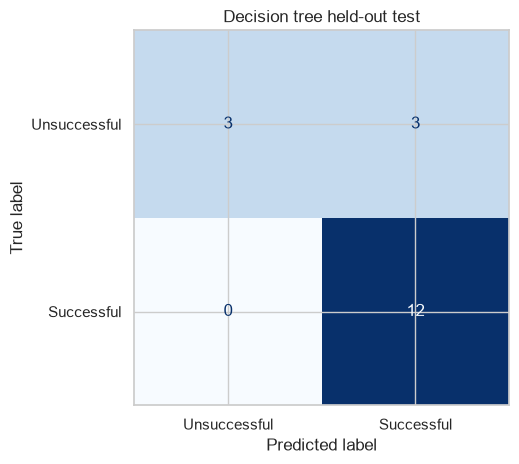

Selected by training CV: Decision tree — test accuracy 0.8333333333333334


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split,StratifiedKFold,GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score,confusion_matrix,ConfusionMatrixDisplay
X=features.copy();y=df.Class
cat=['Orbit','LaunchSite','LandingPad','Serial'];num=[c for c in X.columns if c not in cat]
pre=ColumnTransformer([('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('categorical',Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='Unknown')),('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)])
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=2,stratify=y)
cv=StratifiedKFold(5,shuffle=True,random_state=2)
specs={
'Logistic regression':(LogisticRegression(max_iter=3000),{'model__C':[.01,.1,1,10,100]}),
'SVM':(SVC(),{'model__C':[.1,1,10],'model__kernel':['linear','rbf'],'model__gamma':['scale',.01,.1]}),
'Decision tree':(DecisionTreeClassifier(random_state=2),{'model__max_depth':[2,3,4,6,None],'model__min_samples_leaf':[1,2,4]}),
'KNN':(KNeighborsClassifier(),{'model__n_neighbors':[3,5,7,9],'model__weights':['uniform','distance'],'model__p':[1,2]})}
models={};metrics=[]
for name,(est,grid) in specs.items():
    search=GridSearchCV(Pipeline([('preprocess',pre),('model',est)]),grid,cv=cv,scoring='accuracy',n_jobs=1)
    search.fit(X_train,y_train);models[name]=search
    pred=search.predict(X_test)
    metrics.append({'Model':name,'CV accuracy':search.best_score_,'CV std':search.cv_results_['std_test_score'][search.best_index_],'Test accuracy':accuracy_score(y_test,pred),'Balanced accuracy':balanced_accuracy_score(y_test,pred),'F1':f1_score(y_test,pred),'Parameters':str(search.best_params_)})
metrics=pd.DataFrame(metrics).sort_values('CV accuracy',ascending=False);display(metrics)
best=metrics.iloc[0].Model;pred=models[best].predict(X_test);cm=confusion_matrix(y_test,pred)
ConfusionMatrixDisplay(cm,display_labels=['Unsuccessful','Successful']).plot(cmap='Blues',colorbar=False);plt.title(best+' held-out test');save('confusion_matrix')
metrics.to_csv(BASE/'model_results.csv',index=False)
summary={'n':len(df),'successes':int(df.Class.sum()),'success_rate':float(df.Class.mean()),'site':site.reset_index().to_dict('records'),'year':year.reset_index().to_dict('records'),'orbit':orbit.reset_index().to_dict('records'),'model_results':metrics.to_dict('records'),'best_model':best,'confusion_matrix':cm.tolist(),'proximity_km':prox,'web_records':len(web),'test_rows':len(y_test),'test_successes':int(y_test.sum())}
(BASE/'analysis_summary.json').write_text(json.dumps(summary,indent=2))
print('Selected by training CV:',best,'— test accuracy',accuracy_score(y_test,pred))


## Conclusions
Landing success improves over the observed period, but launch-site and orbit comparisons involve small, non-random groups. The 90-row API sample has 60 successful first-stage outcomes (66.7%). Successful ocean outcomes count as success in the course target, even though they do not necessarily represent recovery suitable for reuse. Cost estimates should therefore model reusable recovery separately. Model accuracy on just 18 test rows is uncertain. One error changes accuracy by 5.6 percentage points. Use the dashboard for exploration and validate on recent chronological data before any operational or pricing decision.

## Sources
- Official course API snapshot: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/API_call_spacex_api.json
- Official course enriched data: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_1.csv
- Official course SQL data: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/labs/module_2/data/Spacex.csv
- Wikipedia revision: https://en.wikipedia.org/w/index.php?title=List_of_Falcon_9_and_Falcon_Heavy_launches&oldid=1027686922
